<a href="https://colab.research.google.com/github/uiwoos2/26-2-DIP-202202515/blob/main/HW/HW02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## HW02
202202515 이수민

## Exercise
- 두 개의 noisy image를 각각 f1, f2로 불러오고 적절한 restoration(denoising)을 수행해보자.

In [57]:
import numpy as np
import matplotlib.pyplot as plt

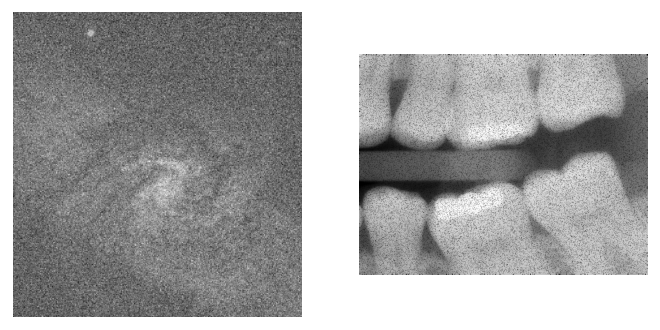

In [58]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

- 복원코드를 직접 작성해보기.

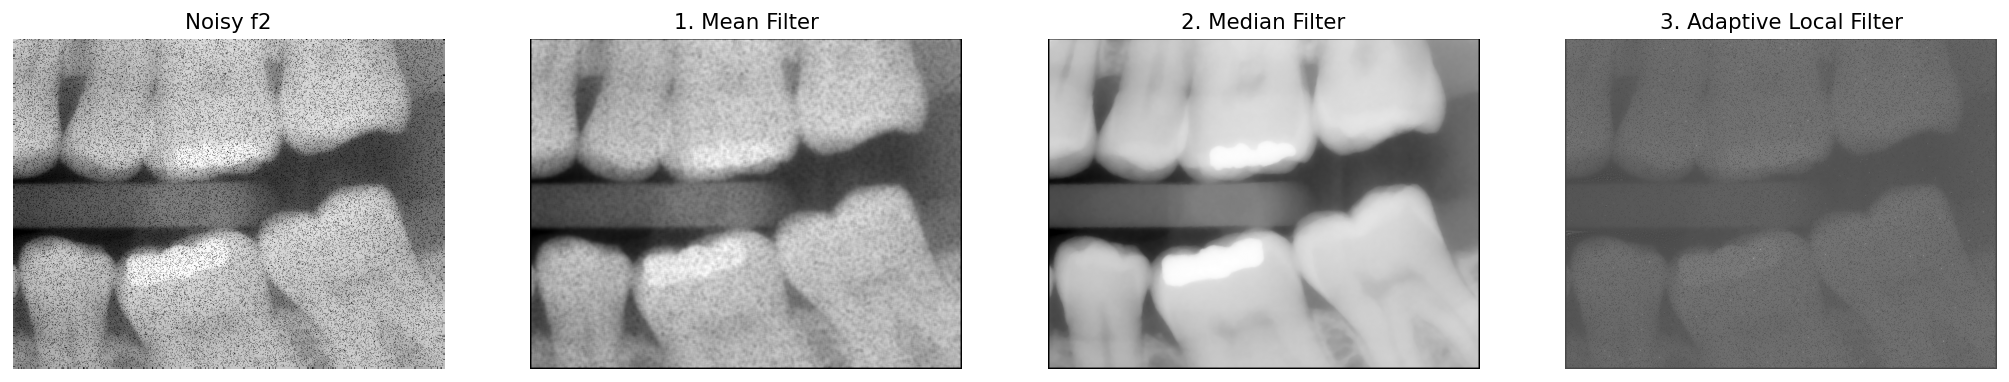

In [64]:
SS = 7
ss = int((SS-1)/2)
std_eta = 16

f1_r = np.zeros(np.shape(f1))
r_mean = np.zeros(np.shape(f2))
r_median = np.zeros(np.shape(f2))
r_amean = np.zeros(np.shape(f2))


#Arithmetic Mean & Median Filter
for x in range(ss, np.size(f2, 0) - ss):
    for y in range(ss, np.size(f2, 1) - ss):
        Sxy = f2[x-ss : x-ss+SS, y-ss : y-ss+SS]
        r_mean[x, y] = np.mean(Sxy)
        r_median[x, y] = np.median(Sxy)


#Adaptive local noise reduction
for x in range(ss, np.size(f2, 0) - ss):
    for y in range(ss, np.size(f2, 1) - ss):
        Sxy = f2[x-ss : x-ss+SS, y-ss : y-ss+SS]
        std_Sxy = np.std(Sxy)
        var_Sxy = std_Sxy * std_Sxy if std_Sxy != 0 else 1e-8
        r_amean[x, y] = f2[x, y] - ((std_eta * std_eta) / var_Sxy) * (f2[x, y] - np.mean(Sxy))

# 3가지 경우 모두 시각화 진행했습니다.
plt.figure(figsize=(20, 5), dpi=128)
plt.subplot(141)
plt.imshow(f2, cmap='gray')
plt.title('Noisy f2')
plt.axis('off')

plt.subplot(142)
plt.imshow(r_mean, cmap='gray')
plt.title('1. Mean Filter')
plt.axis('off')

plt.subplot(143)
plt.imshow(r_median, cmap='gray')
plt.title('2. Median Filter')
plt.axis('off')

plt.subplot(144)
plt.imshow(r_amean, cmap='gray')
plt.title('3. Adaptive Local Filter')
plt.axis('off')
plt.show()

#medain이 가장 우수하다고 판단하였습니다.
f2_r = r_median


- 복원된 f1, f2를 시각화하기

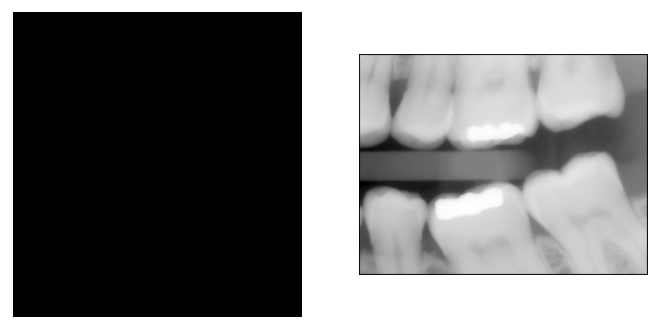

In [65]:
# f1_r: denoised f1
# f2_r: denoised f2
plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1_r,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2_r,cmap='gray')
plt.axis('off')
plt.show()

- 복원된 f1, f2를 그림파일로 저장하기

In [ ]:
plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray')
plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray')